# Week 4 Tasks

Each task has a short description followed by its code.

## Task 1 — Top K Frequent Elements

Given an integer array `nums` and an integer `k`, return the `k` most frequent elements.

In [ ]:
nums = [1, 1, 1, 2, 2, 3]
k = 2

counts = {}
for n in nums:
    counts[n] = counts.get(n, 0) + 1

ordered = sorted(counts, key=lambda x: counts[x], reverse=True)

print(ordered[:k])

[1, 2]


## Task 2 — Search Insert Position

Given a sorted array of distinct integers and a target value, return the index if the target is found. If not, return the index where it would be inserted in order.

In [ ]:
nums = [1, 3, 5, 6]
target = 5

for i in range(len(nums)):
    if nums[i] >= target:
        position = i
        break

print("Index:", position)

Index: 2


## Task 3 — Superstore Sales Analysis

Analyze superstore sales data to identify sales trends, top-performing products, customer behavior, and regional performance using data visualization and statistical techniques.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../SampleSuperstore.csv", encoding="latin-1")
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")

print("Rows:", len(df))
df.head()

Rows: 9994


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [9]:
# Quick summary statistics
print("Total Sales:  ", round(df["Sales"].sum(), 2))
print("Total Profit: ", round(df["Profit"].sum(), 2))
print("Avg Discount: ", round(df["Discount"].mean(), 2))
df[["Sales", "Profit", "Quantity", "Discount"]].describe()

Total Sales:   2297200.86
Total Profit:  286397.02
Avg Discount:  0.16


,Sales,Profit,Quantity,Discount
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,3.789574,0.156203
std,623.245101,234.260108,2.225110,0.206452
min,0.444000,-6599.978000,1.000000,0.000000
25%,17.280000,1.728750,2.000000,0.000000
50%,54.490000,8.666500,3.000000,0.200000
75%,209.940000,29.364000,5.000000,0.200000
max,22638.480000,8399.976000,14.000000,0.800000


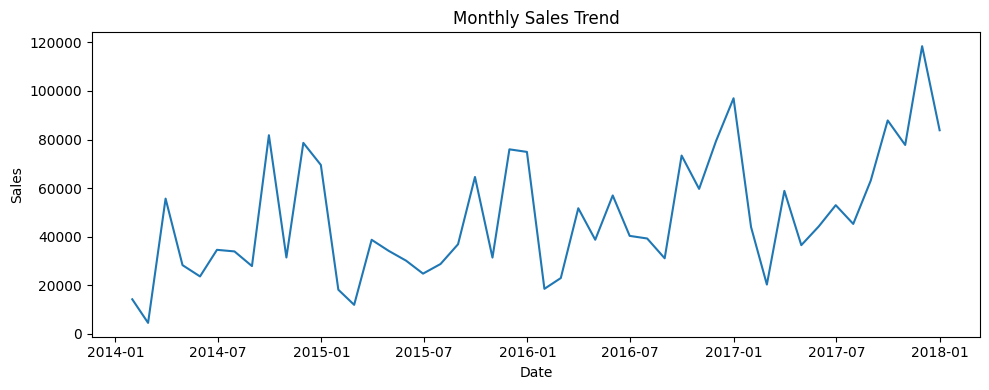

In [10]:
# 1) Sales trend over time (monthly)
monthly = df.set_index("Order Date").resample("ME")["Sales"].sum()

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values)
plt.title("Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

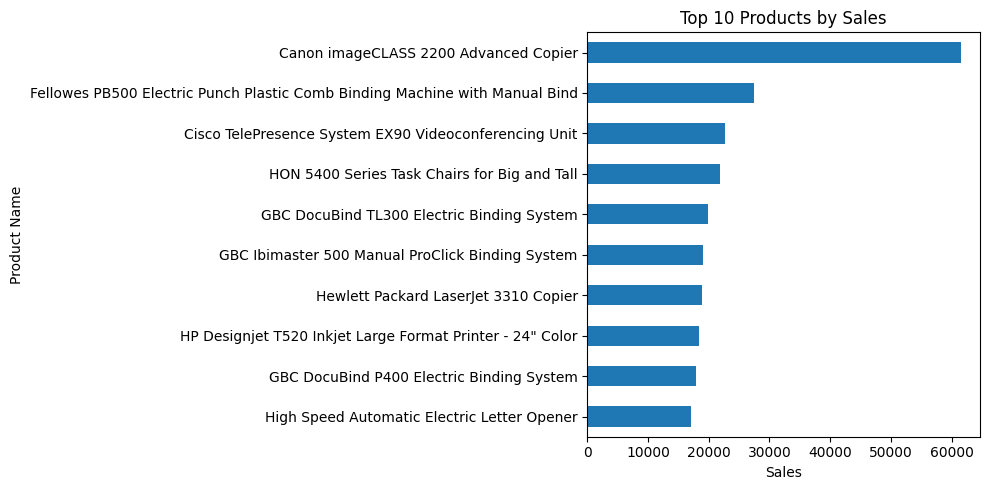

In [11]:
# 2) Top 10 products by sales
top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

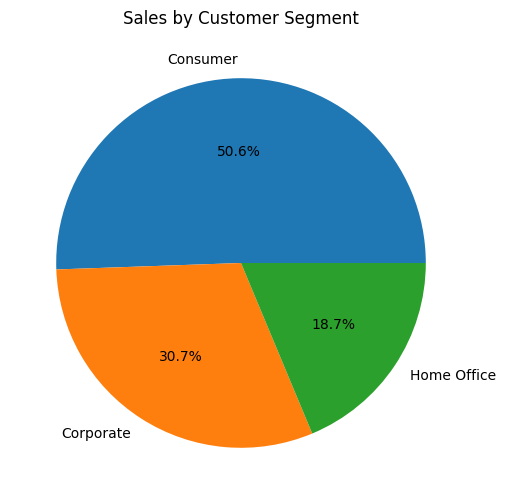

In [12]:
# 3) Customer behaviour: sales by segment
segment_sales = df.groupby("Segment")["Sales"].sum()

plt.figure(figsize=(6, 6))
plt.pie(segment_sales, labels=segment_sales.index, autopct="%1.1f%%")
plt.title("Sales by Customer Segment")
plt.show()

               Sales       Profit
Region                           
Central  501239.8908   39706.3625
East     678781.2400   91522.7800
South    391721.9050   46749.4303
West     725457.8245  108418.4489


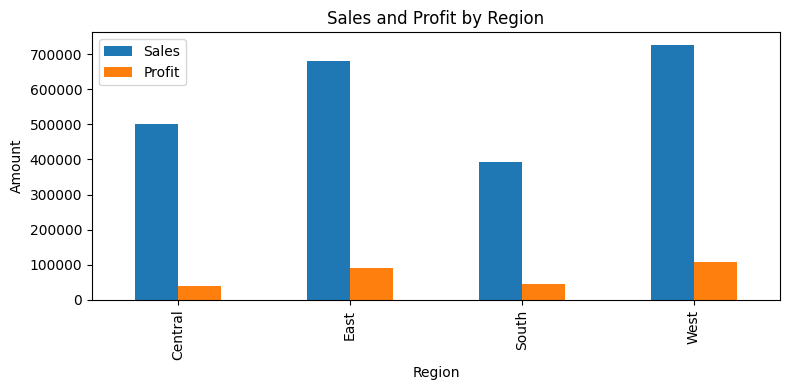

In [13]:
# 4) Regional performance: sales and profit by region
region = df.groupby("Region")[["Sales", "Profit"]].sum()
print(region)

region.plot(kind="bar", figsize=(8, 4))
plt.title("Sales and Profit by Region")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()

## Task 4 — Merge Sorted Array

Given two sorted integer arrays `nums1` and `nums2`, with `m` and `n` valid elements, merge `nums2` into `nums1` so that it stays sorted in non-decreasing order.

In [14]:
nums1 = [1, 2, 3, 0, 0, 0]
m = 3
nums2 = [2, 5, 6]
n = 3

# Keep only the real values, combine, and sort
merged = nums1[:m] + nums2[:n]
merged.sort()

print(merged)

[1, 2, 2, 3, 5, 6]


## Task 5 — 3Sum

Given an integer array `nums`, return all unique triplets `[nums[i], nums[j], nums[k]]` where the three indices are different and the values add up to `0`.

In [15]:
nums = [-1, 0, 1, 2, -1, -4]

triplets = []
for i in range(len(nums)):
    for j in range(i + 1, len(nums)):
        for k in range(j + 1, len(nums)):
            if nums[i] + nums[j] + nums[k] == 0:
                triplet = sorted([nums[i], nums[j], nums[k]])
                if triplet not in triplets:
                    triplets.append(triplet)

print(triplets)

[[-1, 0, 1], [-1, -1, 2]]
